Para proyectar cada entidad federativa hacia 2030 y 2035 usando la ecuación logística:$$P(t) = \frac{K}{1 + \left(\frac{K - P_0}{P_0}\right) e^{-r(t - t_0)}}$$Reescalamiento temporal ($t - t_0$): Tomamos $t_0 = 1910$ (primer año de la serie histórica) y fijamos $P_0 = P(1910)$ para evitar desbordamientos numéricos en la exponencial $\exp(-rt)$.Ajuste no lineal (scipy.optimize.curve_fit): Ajustamos simultáneamente la capacidad de carga $K$ y la tasa intrínseca $r$ para cada estado usando Mínimos Cuadrados No Lineales con cotas físicas ($K > P_{\text{máx actual}}$ para estados en crecimiento).Proyección de Densidad y Población Productiva (15-64 años):Como la superficie territorial $S$ de cada estado es constante ($S = \frac{P_{2025}}{\text{Densidad}_{2025}}$), la densidad proyectada en 2030 y 2035 es simplemente $\text{Densidad}(t) = \frac{P(t)}{S}$.Para la población de 15 a 64 años proyectada, conservamos la proporción demográfica reciente o ajustamos su tendencia respecto al total estatal.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit

# Cargar el Parquet limpio desde data/processed/
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
RUTA_PARQUET = BASE_DIR / "data" / "processed" / "demografia_inegi_estatal.parquet"

df = pd.read_parquet(RUTA_PARQUET)
print(f"Total de registros cargados: {len(df)}")
df.head()

Total de registros cargados: 544


,Anio,Poblacion_Total,Densidad_Pob,Pob_15_a_64,Saldo_Migratorio_Interno,CVE_ENT,Entidad,Fecha
0,1900,NaN,18.3,NaN,NaN,01,Aguascalientes,1900-01-01
1,1910,120511.0,15.7,NaN,NaN,01,Aguascalientes,1910-01-01
2,1921,107581.0,16.6,NaN,NaN,01,Aguascalientes,1921-01-01
3,1930,132900.0,20.5,NaN,NaN,01,Aguascalientes,1930-01-01
4,1940,161693.0,25.0,NaN,NaN,01,Aguascalientes,1940-01-01


In [2]:
def modelo_logistico(t, K, r, t0, P0):
    """Ecuación logística exacta anclada en (t0, P0)."""
    return K / (1.0 + ((K - P0) / P0) * np.exp(-r * (t - t0)))


def proyectar_estado(df_estado, anios_futuros=[2030, 2035]):
    """Ajusta los parámetros K y r para un estado y proyecta hacia 2030 y 2035."""
    df_val = df_estado.dropna(subset=["Poblacion_Total"]).sort_values("Anio")

    t_data = df_val["Anio"].values.astype(float)
    p_data = df_val["Poblacion_Total"].values.astype(float)

    t0 = t_data[0]
    P0 = p_data[0]
    p_max = p_data.max()

    # Función wrapper que fija t0 y P0 para optimizar solo K y r
    def func_ajuste(t, K, r):
        return modelo_logistico(t, K, r, t0, P0)

    # Semillas iniciales: K = 2 veces la población actual, r = 0.025 (2.5% anual)
    p0_guess = [p_max * 2.0, 0.025]
    # Cotas físicas: K entre 1.01*p_max y 10*p_max; r entre -0.05 y 0.15
    bounds = ([p_max * 1.01, -0.05], [p_max * 10.0, 0.15])

    popt, _ = curve_fit(
        func_ajuste, t_data, p_data, p0=p0_guess, bounds=bounds, maxfev=10000
    )
    K_opt, r_opt = popt

    # Calcular superficie implícita (km²) y proporción 15-64 del último año (2025)
    fila_2025 = df_val[df_val["Anio"] == 2025].iloc[0]
    superficie_km2 = fila_2025["Poblacion_Total"] / fila_2025["Densidad_Pob"]
    prop_15_64 = fila_2025["Pob_15_a_64"] / fila_2025["Poblacion_Total"]

    # Generar filas proyectadas
    nuevas_filas = []
    for anio in anios_futuros:
        pob_proy = float(func_ajuste(anio, K_opt, r_opt))
        nuevas_filas.append({
            "Anio": int(anio),
            "Fecha": pd.to_datetime(f"{anio}-01-01"),
            "CVE_ENT": fila_2025["CVE_ENT"],
            "Entidad": fila_2025["Entidad"],
            "Poblacion_Total": round(pob_proy, 0),
            "Densidad_Pob": round(pob_proy / superficie_km2, 4),
            "Pob_15_a_64": round(pob_proy * prop_15_64, 0),
            "Saldo_Migratorio_Interno": np.nan,
            "Tipo_Dato": "Proyección Logística",
            "K_Capacidad": round(K_opt, 0),
            "r_Tasa": round(r_opt, 5),
        })

    return pd.DataFrame(nuevas_filas), K_opt, r_opt, func_ajuste

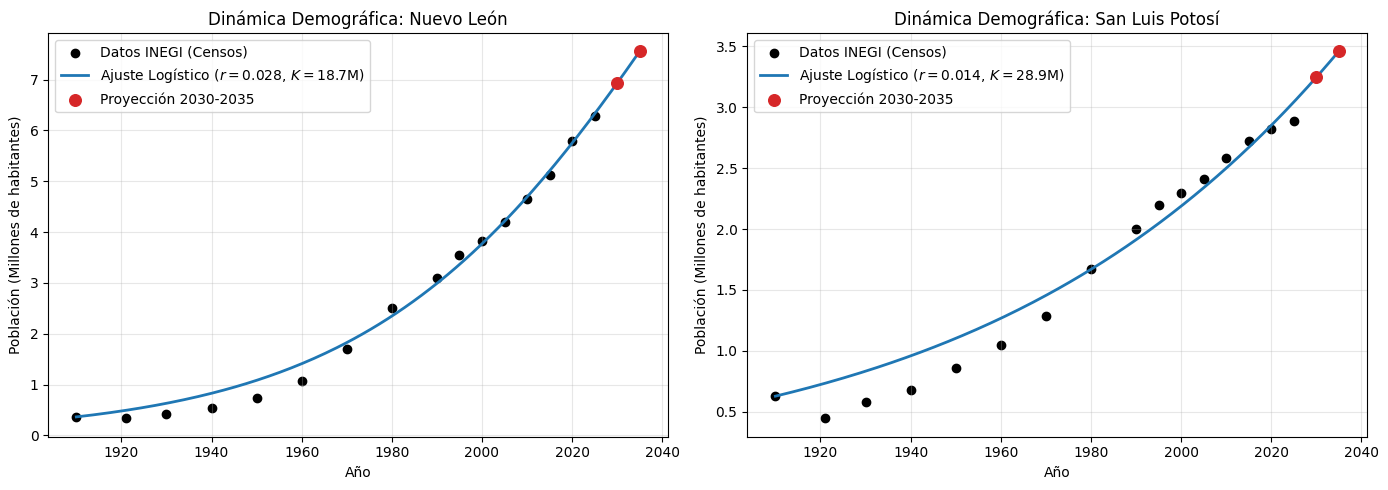

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
estados_ejemplo = [("19", "Nuevo León"), ("24", "San Luis Potosí")]

for ax, (cve, nombre) in zip(axes, estados_ejemplo):
    df_est = df[df["CVE_ENT"] == cve]
    df_proy, K_opt, r_opt, func_ajuste = proyectar_estado(df_est)

    t_curva = np.linspace(1910, 2035, 200)
    ax.scatter(
        df_est["Anio"],
        df_est["Poblacion_Total"] / 1e6,
        color="black",
        label="Datos INEGI (Censos)",
    )
    ax.plot(
        t_curva,
        func_ajuste(t_curva, K_opt, r_opt) / 1e6,
        color="tab:blue",
        lw=2,
        label=f"Ajuste Logístico ($r={r_opt:.3f}$, $K={K_opt/1e6:.1f}$M)",
    )
    ax.scatter(
        df_proy["Anio"],
        df_proy["Poblacion_Total"] / 1e6,
        color="tab:red",
        s=70,
        zorder=5,
        label="Proyección 2030-2035",
    )

    ax.set_title(f"Dinámica Demográfica: {nombre}")
    ax.set_xlabel("Año")
    ax.set_ylabel("Población (Millones de habitantes)")
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

In [4]:
df["Tipo_Dato"] = "Histórico Censal"
df["K_Capacidad"] = np.nan
df["r_Tasa"] = np.nan

proyecciones = []
for cve, grupo in df.groupby("CVE_ENT"):
    df_proy, K_opt, r_opt, _ = proyectar_estado(grupo)
    # Asignar K y r también a las filas históricas del estado para consultarlos en Power BI
    df.loc[df["CVE_ENT"] == cve, "K_Capacidad"] = round(K_opt, 0)
    df.loc[df["CVE_ENT"] == cve, "r_Tasa"] = round(r_opt, 5)
    proyecciones.append(df_proy)

df_completo = pd.concat([df] + proyecciones, ignore_index=True).sort_values(
    ["CVE_ENT", "Anio"]
)

# Comparativa 2025 vs 2035 por estado
pob_2025 = df_completo[df_completo["Anio"] == 2025].set_index("Entidad")[
    "Poblacion_Total"
]
pob_2035 = df_completo[df_completo["Anio"] == 2035].set_index("Entidad")[
    "Poblacion_Total"
]

resumen_10_anios = pd.DataFrame({
    "Pob_2025": pob_2025,
    "Pob_2035_Proyectada": pob_2035,
    "Crecimiento_Neto_Hab": pob_2035 - pob_2025,
    "Crecimiento_Porcentual_%": ((pob_2035 - pob_2025) / pob_2025) * 100,
}).sort_values("Crecimiento_Porcentual_%", ascending=False)

print("Top 10 estados con mayor presión demográfica proyectada (2025 -> 2035):")
resumen_10_anios.head(10)

Top 10 estados con mayor presión demográfica proyectada (2025 -> 2035):


,Pob_2025,Pob_2035_Proyectada,Crecimiento_Neto_Hab,Crecimiento_Porcentual_%
Entidad,,,,
Baja California Sur,961514.0,1240052.0,278538.0,28.968689
Campeche,968673.0,1217017.0,248344.0,25.637547
Aguascalientes,1539174.0,1932838.0,393664.0,25.576316
Colima,762212.0,956536.0,194324.0,25.494744
Chiapas,5860728.0,7239577.0,1378849.0,23.526924
Morelos,1997217.0,2453607.0,456390.0,22.851298
Guerrero,3418902.0,4173540.0,754638.0,22.072525
Jalisco,8679851.0,10558479.0,1878628.0,21.643551
México,17612480.0,21341645.0,3729165.0,21.173424
